In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr


import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

In [ ]:
import pandas as pd
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)
print(f"Kích thước bộ dữ liệu: {df.shape}")
df.head()


Kích thước bộ dữ liệu: (507, 22)


,ID,Truong,Khoi,Phai,tg_sudung_dt,Q1,Q2,Q3,Q4,Q5,...,Q8,Q9,Q10,Tong,addiction,Level,id,name,rating,created_at
0,anhn85782@gmail.com,1,1,0,7.0,4,4,2,4,2,...,2,5,3,38.0,0.63,1,NaN,NaN,NaN,NaN
1,thu.nnm1812-k32sinh@thd.edu.vn,1,1,0,5.0,5,4,4,2,4,...,4,5,2,40.0,0.67,2,NaN,NaN,NaN,NaN
2,lucyngoc2009@gmail.com,1,1,0,8.0,2,5,3,3,2,...,5,5,2,44.0,0.73,2,NaN,NaN,NaN,NaN
3,trang.ndh-k32sinh@thd.edu.vn,1,1,0,4.0,4,4,4,4,4,...,2,5,2,37.0,0.62,1,NaN,NaN,NaN,NaN
4,ngamy160709@gmail.com,1,1,0,4.0,4,1,1,1,1,...,4,1,1,23.0,0.38,0,NaN,NaN,NaN,NaN


📊 THỐNG KÊ SỐ LƯỢNG NHÃN TRÊN TẬP df1 (Tổng: 507 mẫu)
    Nhãn mức độ  Số lượng mẫu  Tỷ lệ (%)
      L0 (Thấp)           139      27.42
L1 (Trung bình)           287      56.61
       L2 (Cao)            81      15.98


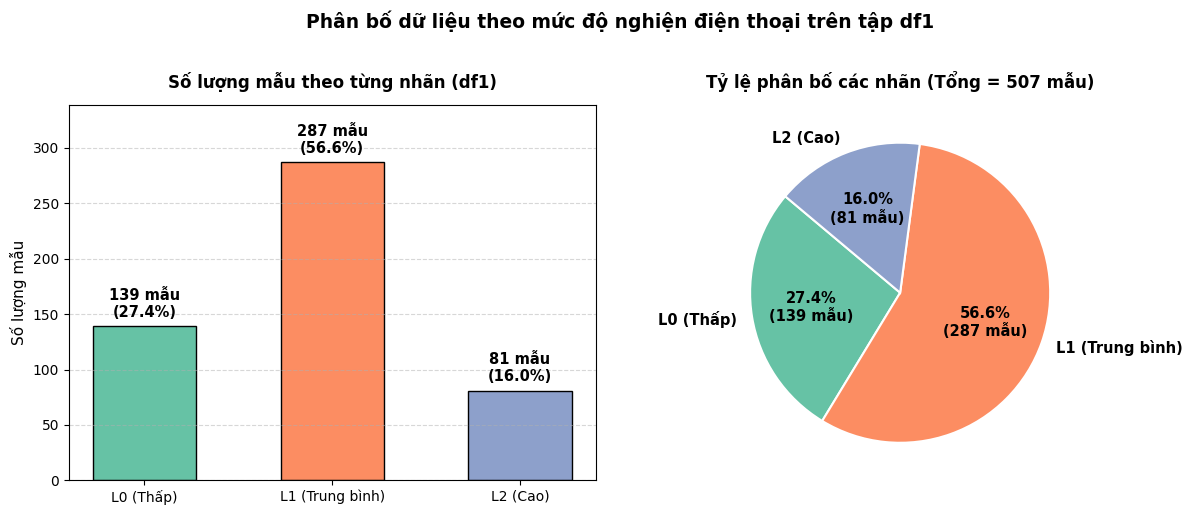

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. ĐỌC DỮ LIỆU df1 & CHUẨN HÓA CỘT NHÃN 'Level'
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)
Y = df['Level'].copy()

if Y.dtype == 'object' or Y.dtype.name == 'category':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce').dropna().astype(int)
if len(Y) > 0 and Y.min() == 1:
    Y = Y - 1

# =========================================================================
# 2. THỐNG KÊ & IN SỐ LƯỢNG L0, L1, L2 TRÊN df1
# =========================================================================
label_names = ['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)']
counts = [int((Y == i).sum()) for i in [0, 1, 2]]
total = sum(counts)
percentages = [(c / total * 100) if total > 0 else 0 for c in counts]

df_dist = pd.DataFrame({
    'Nhãn mức độ': label_names,
    'Số lượng mẫu': counts,
    'Tỷ lệ (%)': [round(p, 2) for p in percentages]
})

print("=" * 52)
print(f"📊 THỐNG KÊ SỐ LƯỢNG NHÃN TRÊN TẬP df1 (Tổng: {total} mẫu)")
print("=" * 52)
print(df_dist.to_string(index=False))
print("=" * 52)

# =========================================================================
# 3. VẼ BIỂU ĐỒ PHÂN BỐ SỐ LƯỢNG & TỶ LỆ L0, L1, L2
# =========================================================================
colors = ['#66c2a5', '#fc8d62', '#8da0cb']
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

# Biểu đồ cột (số lượng + phần trăm)
bars = axes[0].bar(label_names, counts, color=colors, edgecolor='black', width=0.55)
for bar, count, pct in zip(bars, counts, percentages):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(counts) * 0.02,
        f"{count} mẫu\n({pct:.1f}%)",
        ha='center', va='bottom', fontsize=10.5, fontweight='bold'
    )
axes[0].set_title('Số lượng mẫu theo từng nhãn (df1)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('Số lượng mẫu', fontsize=11)
axes[0].set_ylim(0, max(counts) * 1.18)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ tròn (tỷ lệ phần trăm)
axes[1].pie(
    counts,
    labels=label_names,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * total / 100))} mẫu)',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10.5, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
axes[1].set_title(f'Tỷ lệ phân bố các nhãn (Tổng = {total} mẫu)', fontsize=12, fontweight='bold', pad=12)

plt.suptitle('Phân bố dữ liệu theo mức độ nghiện điện thoại trên tập df1', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Phan_bo_L0_L1_L2_df1.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)

cols = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
X = df[[c for c in cols if c in df.columns]].apply(pd.to_numeric, errors='coerce')
Y = df['Level'].replace({'L0': 0, 'L1': 1, 'L2': 2})
Y = pd.to_numeric(Y, errors='coerce')

# Lọc dòng hợp lệ, điền ô trống bằng median và tạo 3 đặc trưng tổng hợp
valid = Y.notna()
X, Y = X[valid].fillna(X[valid].median()).fillna(0), Y[valid].astype(int)
q_cols = [c for c in cols[1:] if c in X.columns]
X['Q_mean'] = X[q_cols].mean(axis=1)
X['Q_std']  = X[q_cols].std(axis=1)
X['Q_max']  = X[q_cols].max(axis=1)
# 1. Chia dữ liệu: 70% Train - 15% Validation - 15% Test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, Y,
    test_size=0.15,
    random_state=42,
    stratify=Y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=(15 / 85),
    random_state=42,
    stratify=y_temp
)

# 2. Chuẩn hóa & SMOTE trên tập Train (sẵn sàng cho mô hình học ở bước sau)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

# 3. Đếm số lượng mẫu, tỷ lệ % và phân bố từng lớp
tong = len(Y)
def dem_lop(y):
    return dict(pd.Series(y).value_counts().sort_index())

print(f"Tổng dữ liệu:     {tong} mẫu (100.0%) | Phân bố: {dem_lop(Y)}")
print(f"Train gốc:        {len(y_train)} mẫu ({len(y_train)/tong*100:.1f}%) | Phân bố: {dem_lop(y_train)}")
print(f"Train sau SMOTE:  {len(y_train_res)} mẫu          | Phân bố: {dem_lop(y_train_res)}")
print(f"Validation:       {len(y_val)} mẫu ({len(y_val)/tong*100:.1f}%)  | Phân bố: {dem_lop(y_val)}")
print(f"Test:             {len(y_test)} mẫu ({len(y_test)/tong*100:.1f}%)  | Phân bố: {dem_lop(y_test)}")

Tổng dữ liệu:     507 mẫu (100.0%) | Phân bố: {0: np.int64(139), 1: np.int64(287), 2: np.int64(81)}
Train gốc:        354 mẫu (69.8%) | Phân bố: {0: np.int64(97), 1: np.int64(200), 2: np.int64(57)}
Train sau SMOTE:  600 mẫu          | Phân bố: {0: np.int64(200), 1: np.int64(200), 2: np.int64(200)}
Validation:       76 mẫu (15.0%)  | Phân bố: {0: np.int64(21), 1: np.int64(43), 2: np.int64(12)}
Test:             77 mẫu (15.2%)  | Phân bố: {0: np.int64(21), 1: np.int64(44), 2: np.int64(12)}


In [ ]:
import pandas as pd
import numpy as np

# Kiểm tra xem Cell 1 đã chạy chưa; nếu chưa thì báo rõ để chạy Cell 1 trước
required_vars = ['y_train', 'y_val', 'y_test', 'y_train_res']
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(f"⚠️ Bạn chưa chạy Cell 1! Hãy bấm chạy Cell 1 phía trên trước để tạo các biến: {missing_vars}")

# ==========================================
# 6. THỐNG KÊ SỐ LƯỢNG & TỶ LỆ L0, L1, L2 TRÊN TỪNG TẬP (70/15/15)
# ==========================================
def thong_ke_phan_bo(splits_dict):
    all_y = np.concatenate([np.asarray(y) for y in splits_dict.values()])
    unique_classes = sorted(np.unique(all_y))

    # Lấy tên nhãn chuẩn ('L0', 'L1', 'L2')
    if 'le' in globals() and hasattr(le, 'classes_') and len(le.classes_) == len(unique_classes):
        label_names = list(le.classes_)
    else:
        label_names = [f"L{int(c)}" for c in unique_classes]

    rows = []
    for name, y_data in splits_dict.items():
        y_arr = np.asarray(y_data)
        total = len(y_arr)
        row = {
            'Tập dữ liệu': name,
            'Tổng mẫu': total
        }
        for cls_val, lbl in zip(unique_classes, label_names):
            count = int(np.sum(y_arr == cls_val))
            pct = (count / total * 100) if total > 0 else 0.0
            row[f'{lbl} (Số lượng / Tỷ lệ)'] = f"{count} ({pct:.2f}%)"
        rows.append(row)

    return pd.DataFrame(rows)

df_phan_bo = thong_ke_phan_bo({
    'Tập Train gốc (70%)': y_train,
    'Tập Validation (15%)': y_val,
    'Tập Test (15%)': y_test,
    'Tập Train sau SMOTE': y_train_res
})

print("=" * 95)
print("📊 THỐNG KÊ SỐ LƯỢNG VÀ TỶ LỆ NHÃN L0, L1, L2 THEO TỶ LỆ CHIA 70/15/15")
print("=" * 95)
print(df_phan_bo.to_string(index=False))
print("=" * 95)

📊 THỐNG KÊ SỐ LƯỢNG VÀ TỶ LỆ NHÃN L0, L1, L2 THEO TỶ LỆ CHIA 70/15/15
         Tập dữ liệu  Tổng mẫu L0 (Số lượng / Tỷ lệ) L1 (Số lượng / Tỷ lệ) L2 (Số lượng / Tỷ lệ)
 Tập Train gốc (70%)       354           97 (27.40%)          200 (56.50%)           57 (16.10%)
Tập Validation (15%)        76           21 (27.63%)           43 (56.58%)           12 (15.79%)
      Tập Test (15%)        77           21 (27.27%)           44 (57.14%)           12 (15.58%)
 Tập Train sau SMOTE       600          200 (33.33%)          200 (33.33%)          200 (33.33%)


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc và gộp dữ liệu (507 mẫu)
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

# Chuẩn hóa nhãn Y an toàn
if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce')

valid_idx = Y.notna()
X_original = X_original[valid_idx].apply(pd.to_numeric, errors='coerce')
Y = Y[valid_idx].astype(int)

# Tạo đặc trưng tổng hợp từ nhóm câu hỏi Q1 - Q10
q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)
    X_original['Q_std']  = X_original[q_cols].std(axis=1)
    X_original['Q_max']  = X_original[q_cols].max(axis=1)

print(f"✅ Đã đọc xong dữ liệu: {len(Y)} mẫu hợp lệ | Số đặc trưng: {X_original.shape[1]}")

✅ Đã đọc xong dữ liệu: 507 mẫu hợp lệ | Số đặc trưng: 14


In [ ]:
RANDOM_SEED = 42  # Có thể đổi sang 7 nếu muốn đồng bộ với các thực nghiệm trước

X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.15, random_state=RANDOM_SEED, stratify=Y
)

print(f"📌 Tập Train + Val (85%): {len(X_train_raw)} mẫu")
print(f"📌 Tập Test độc lập (15%): {len(X_test_raw)} mẫu")

📌 Tập Train + Val (85%): 430 mẫu
📌 Tập Test độc lập (15%): 77 mẫu


In [ ]:
def create_optimized_fnn(input_dim, output_classes):
    model = Sequential([
        Input(shape=(input_dim,)),

        Dense(64, activation='mish'),
        Dropout(0.15),

        Dense(32, activation='mish'),
        Dropout(0.1),

        Dense(output_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.002),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.03),
        metrics=['accuracy']
    )
    return model

# Kiểm tra thử cấu trúc mạng
sample_model = create_optimized_fnn(input_dim=X_train_raw.shape[1], output_classes=len(np.unique(Y)))
sample_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,139 (12.26 KB)

 Trainable params: 3,139 (12.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)

output_classes = len(np.unique(Y))
test_predictions_folds = np.zeros((len(X_test_raw), output_classes))
oof_predictions = np.zeros((len(X_train_raw), output_classes))

print(f"🚀 Bắt đầu huấn luyện {n_splits}-Fold Optimized Ensemble FNN ({len(Y)} mẫu)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    tf.keras.backend.clear_session()
    tf.random.set_seed(RANDOM_SEED + fold)

    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    # Bước A: Điền giá trị khuyết bằng median của tập Train Fold
    fold_medians = X_tr.median()
    X_tr = X_tr.fillna(fold_medians).fillna(0)
    X_val = X_val.fillna(fold_medians).fillna(0)
    X_te = X_te.fillna(fold_medians).fillna(0)

    # Bước B: Cắt ngoại lai IQR cho 'tg_sudung_dt'
    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        upper_bound = Q3 + 1.5 * IQR
        lower_bound = Q1 - 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    # Bước C: Chuẩn hóa StandardScaler trên dữ liệu thật TRƯỚC khi SMOTE
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    # Bước D: Cân bằng lớp bằng SMOTE
    sm = SMOTE(sampling_strategy='auto', random_state=RANDOM_SEED + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr_scaled, Y_tr)

    # Bước E: One-Hot Encoding & Huấn luyện
    Y_tr_one_hot = to_categorical(Y_tr_res, num_classes=output_classes)
    Y_val_one_hot = to_categorical(Y_val, num_classes=output_classes)

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-5, verbose=0)
    ]

    model = create_optimized_fnn(input_dim=X_tr_res.shape[1], output_classes=output_classes)

    model.fit(
        X_tr_res, Y_tr_one_hot,
        epochs=200,
        batch_size=32,
        validation_data=(X_val_scaled, Y_val_one_hot),
        callbacks=callbacks,
        verbose=0
    )

    val_pred_prob = model.predict(X_val_scaled, verbose=0)
    oof_predictions[val_idx] = val_pred_prob
    val_acc = accuracy_score(Y_val, np.argmax(val_pred_prob, axis=1))

    fold_test_pred_prob = model.predict(X_te_scaled, verbose=0)
    test_predictions_folds += fold_test_pred_prob / n_splits

    print(f"✅ Hoàn tất Fold {fold:2d}/{n_splits} | Val Accuracy: {val_acc * 100:.2f}%")

🚀 Bắt đầu huấn luyện 10-Fold Optimized Ensemble FNN (507 mẫu)...
✅ Hoàn tất Fold  1/10 | Val Accuracy: 97.67%
✅ Hoàn tất Fold  2/10 | Val Accuracy: 88.37%
✅ Hoàn tất Fold  3/10 | Val Accuracy: 88.37%
✅ Hoàn tất Fold  4/10 | Val Accuracy: 86.05%
✅ Hoàn tất Fold  5/10 | Val Accuracy: 97.67%
✅ Hoàn tất Fold  6/10 | Val Accuracy: 95.35%
✅ Hoàn tất Fold  7/10 | Val Accuracy: 81.40%
✅ Hoàn tất Fold  8/10 | Val Accuracy: 95.35%
✅ Hoàn tất Fold  9/10 | Val Accuracy: 93.02%
✅ Hoàn tất Fold 10/10 | Val Accuracy: 86.05%


--- KẾT QUẢ 10-FOLD OPTIMIZED ENSEMBLE FNN (DATA MỚI) ---
📊 Độ chính xác trung bình trên 10-Fold Validation (OOF): 90.93%
🎯 Độ chính xác (Accuracy) trên tập Test độc lập (15%):  97.40%

--- BÁO CÁO CHI TIẾT TỪNG NHÓM (PRECISION / RECALL / F1-SCORE) ---
                 precision    recall  f1-score   support

      L0 (Thấp)     1.0000    0.9524    0.9756        21
L1 (Trung bình)     0.9565    1.0000    0.9778        44
       L2 (Cao)     1.0000    0.9167    0.9565        12

       accuracy                         0.9740        77
      macro avg     0.9855    0.9563    0.9700        77
   weighted avg     0.9752    0.9740    0.9739        77

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          20           1           0
Thực tế L1           0          44           0
Thực tế L2           0           1          11

--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0     

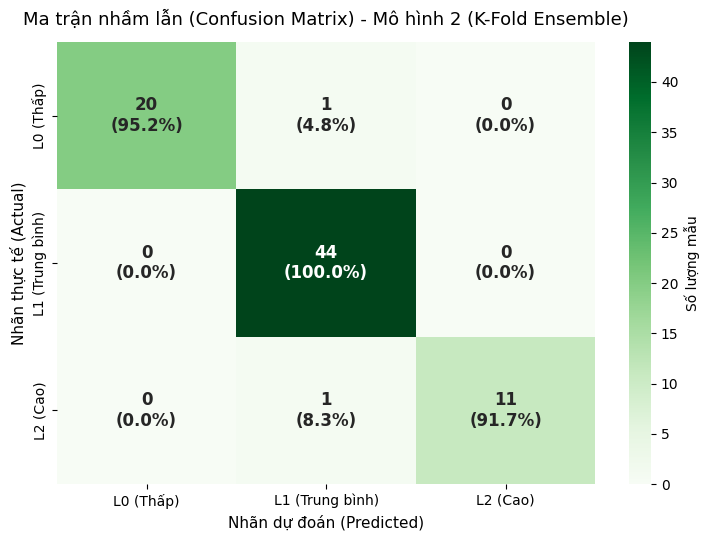

In [ ]:
oof_accuracy = accuracy_score(Y_train_raw, np.argmax(oof_predictions, axis=1))

Y_pred_class = np.argmax(test_predictions_folds, axis=1)
Y_test_class = Y_test_raw.values

cm_count = confusion_matrix(Y_test_class, Y_pred_class)
cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

test_accuracy = accuracy_score(Y_test_class, Y_pred_class)

print("=" * 60)
print("--- KẾT QUẢ 10-FOLD OPTIMIZED ENSEMBLE FNN (DATA MỚI) ---")
print("=" * 60)
print(f"📊 Độ chính xác trung bình trên 10-Fold Validation (OOF): {oof_accuracy * 100:.2f}%")
print(f"🎯 Độ chính xác (Accuracy) trên tập Test độc lập (15%):  {test_accuracy * 100:.2f}%")

print("\n--- BÁO CÁO CHI TIẾT TỪNG NHÓM (PRECISION / RECALL / F1-SCORE) ---")
print(classification_report(
    Y_test_class,
    Y_pred_class,
    target_names=['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)'],
    digits=4
))

print("--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count = pd.DataFrame(
    cm_count,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent = pd.DataFrame(
    cm_percent,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent.astype(str) + '%')
print("=" * 60)

# Vẽ biểu đồ Heatmap
annot_labels = np.empty_like(cm_count, dtype=object)
for i in range(cm_count.shape[0]):
    for j in range(cm_count.shape[1]):
        annot_labels[i, j] = f"{cm_count[i, j]}\n({cm_percent[i, j]:.1f}%)"

labels = ['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)']

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(
    cm_count,
    annot=annot_labels,
    fmt='',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 12, "weight": "bold"},
    cbar_kws={'label': 'Số lượng mẫu'}
)
plt.title('Ma trận nhầm lẫn (Confusion Matrix) - Mô hình 2 (K-Fold Ensemble)', fontsize=13, pad=12)
plt.xlabel('Nhãn dự đoán (Predicted)', fontsize=11)
plt.ylabel('Nhãn thực tế (Actual)', fontsize=11)
plt.tight_layout()
plt.savefig('Confusion_Matrix_FNN_507.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display
from google.colab import files

# Cấu hình hiển thị toàn bộ cột (không bị thu gọn thành dấu '...')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

label_map = {0: 'L0 (Thấp)', 1: 'L1 (Trung bình)', 2: 'L2 (Cao)'}

# Xác định vị trí các ca dự đoán sai trên tập Test
Y_test_class = Y_test_raw.values
Y_pred_class = np.argmax(test_predictions_folds, axis=1)
wrong_mask_m2 = (Y_test_class != Y_pred_class)

# Lấy lại toàn bộ dòng dữ liệu gốc từ df theo đúng Index
wrong_indices_m2 = Y_test_raw.index[wrong_mask_m2]
df_sai_m2 = df.loc[wrong_indices_m2].copy()

# Chèn thêm cột Nhãn thực tế, Nhãn dự đoán và Xác suất dự đoán lên đầu bảng
probs_wrong_m2 = test_predictions_folds[wrong_mask_m2]
df_sai_m2.insert(0, 'Thực_tế', [label_map[y] for y in Y_test_class[wrong_mask_m2]])
df_sai_m2.insert(1, 'Dự_đoán_MH2', [label_map[y] for y in Y_pred_class[wrong_mask_m2]])
df_sai_m2.insert(
    2,
    'Xác_suất_(L0 | L1 | L2)',
    [f"{p[0]*100:.1f}% | {p[1]*100:.1f}% | {p[2]*100:.1f}%" for p in probs_wrong_m2]
)

print(f"=== DANH SÁCH {len(df_sai_m2)} CA DỰ ĐOÁN SAI - MÔ HÌNH 2 (K-FOLD ENSEMBLE) ===")
display(df_sai_m2)

# Xuất ra file Excel để tiện copy vào báo cáo (tùy chọn)
df_sai_m2.to_excel("Ca_du_doan_sai_Mo_hinh_2.xlsx", index=True)
ten_file = "Ca_du_doan_sai_Mo_hinh_2.csv"
df_sai_m2.to_csv(ten_file, index=True, encoding='utf-8-sig')
files.download(ten_file)
print(f"✅ Đã tạo và tải file '{ten_file}' về máy tính!")

=== DANH SÁCH 2 CA DỰ ĐOÁN SAI - MÔ HÌNH 2 (K-FOLD ENSEMBLE) ===


,Thực_tế,Dự_đoán_MH2,Xác_suất_(L0 | L1 | L2),ID,Truong,Khoi,Phai,tg_sudung_dt,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Tong,addiction,Level,id,name,rating,created_at
157,L2 (Cao),L1 (Trung bình),2.0% | 73.3% | 24.7%,ngochando652@gmail.com,0,2,0,5.0,2,5,3,3,4,4,4,3,3,5,41.0,0.68,2,NaN,NaN,NaN,NaN
457,L0 (Thấp),L1 (Trung bình),41.3% | 56.5% | 2.2%,NaN,Trường Trung học Phổ Thông Hàm Thuận Nam,11,Nam,5.0,2,2,2,2,3,3,3,3,2,2,24.0,0.40,0,275.0,NGUYỄN NGỌC QUÝ,5.0,2026-10-16 18:07:06.738351+00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Đã tạo và tải file 'Ca_du_doan_sai_Mo_hinh_2.csv' về máy tính!


📌 Tổng dữ liệu: 507 mẫu | Train (70%): 354 | Val (15%): 76 | Test (15%): 77

🚀 Đang huấn luyện các mô hình cơ sở tiêu chuẩn trên tập Train (70%)...
✅ Hoàn tất: Logistic Regression  | Val Acc (15%): 94.74%
✅ Hoàn tất: SVM - RBF            | Val Acc (15%): 93.42%
✅ Hoàn tất: Random Forest        | Val Acc (15%): 89.47%
✅ Hoàn tất: XGBoost              | Val Acc (15%): 94.74%

📊 BẢNG SO SÁNH FNN ENSEMBLE VỚI CÁC MÔ HÌNH TIÊU CHUẨN (CHIA 70/15/15 - TEST 77 MẪU)
               Mô hình  Val Acc (%)  Test Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1-Score (%)  Weighted F1 (%)  F1 L0 (%)  F1 L1 (%)  F1 L2 (%)
FNN Ensemble (Đề xuất)        90.93              97.40                98.55             95.63               97.00            97.39      97.56      97.78      95.65
   Logistic Regression        94.74              96.10                97.87             92.86               95.06            96.03      97.56      96.70      90.91
               XGBoost        94.74           

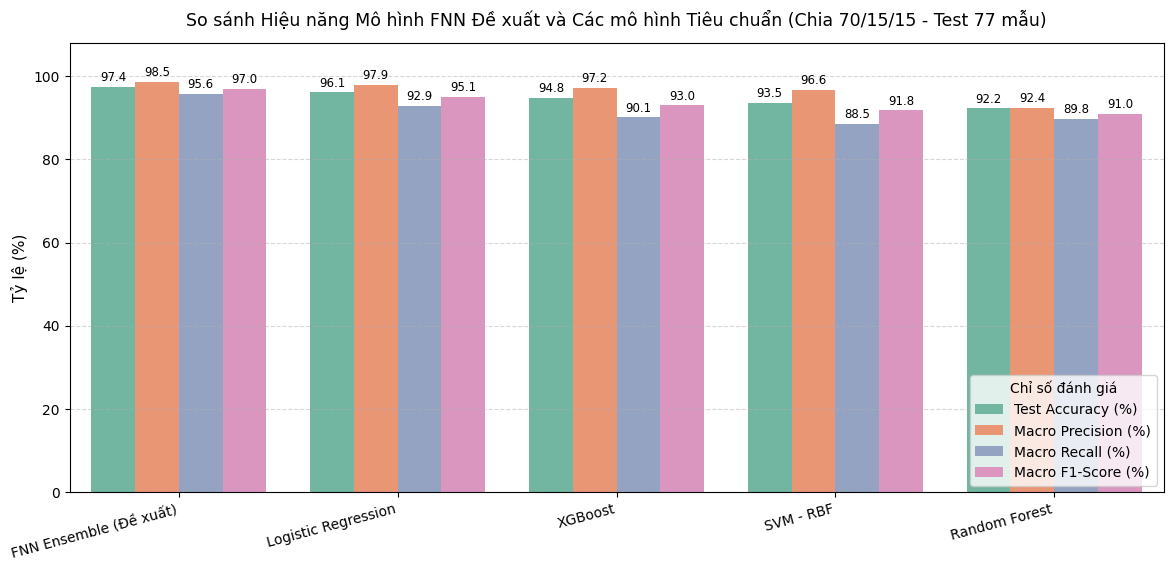

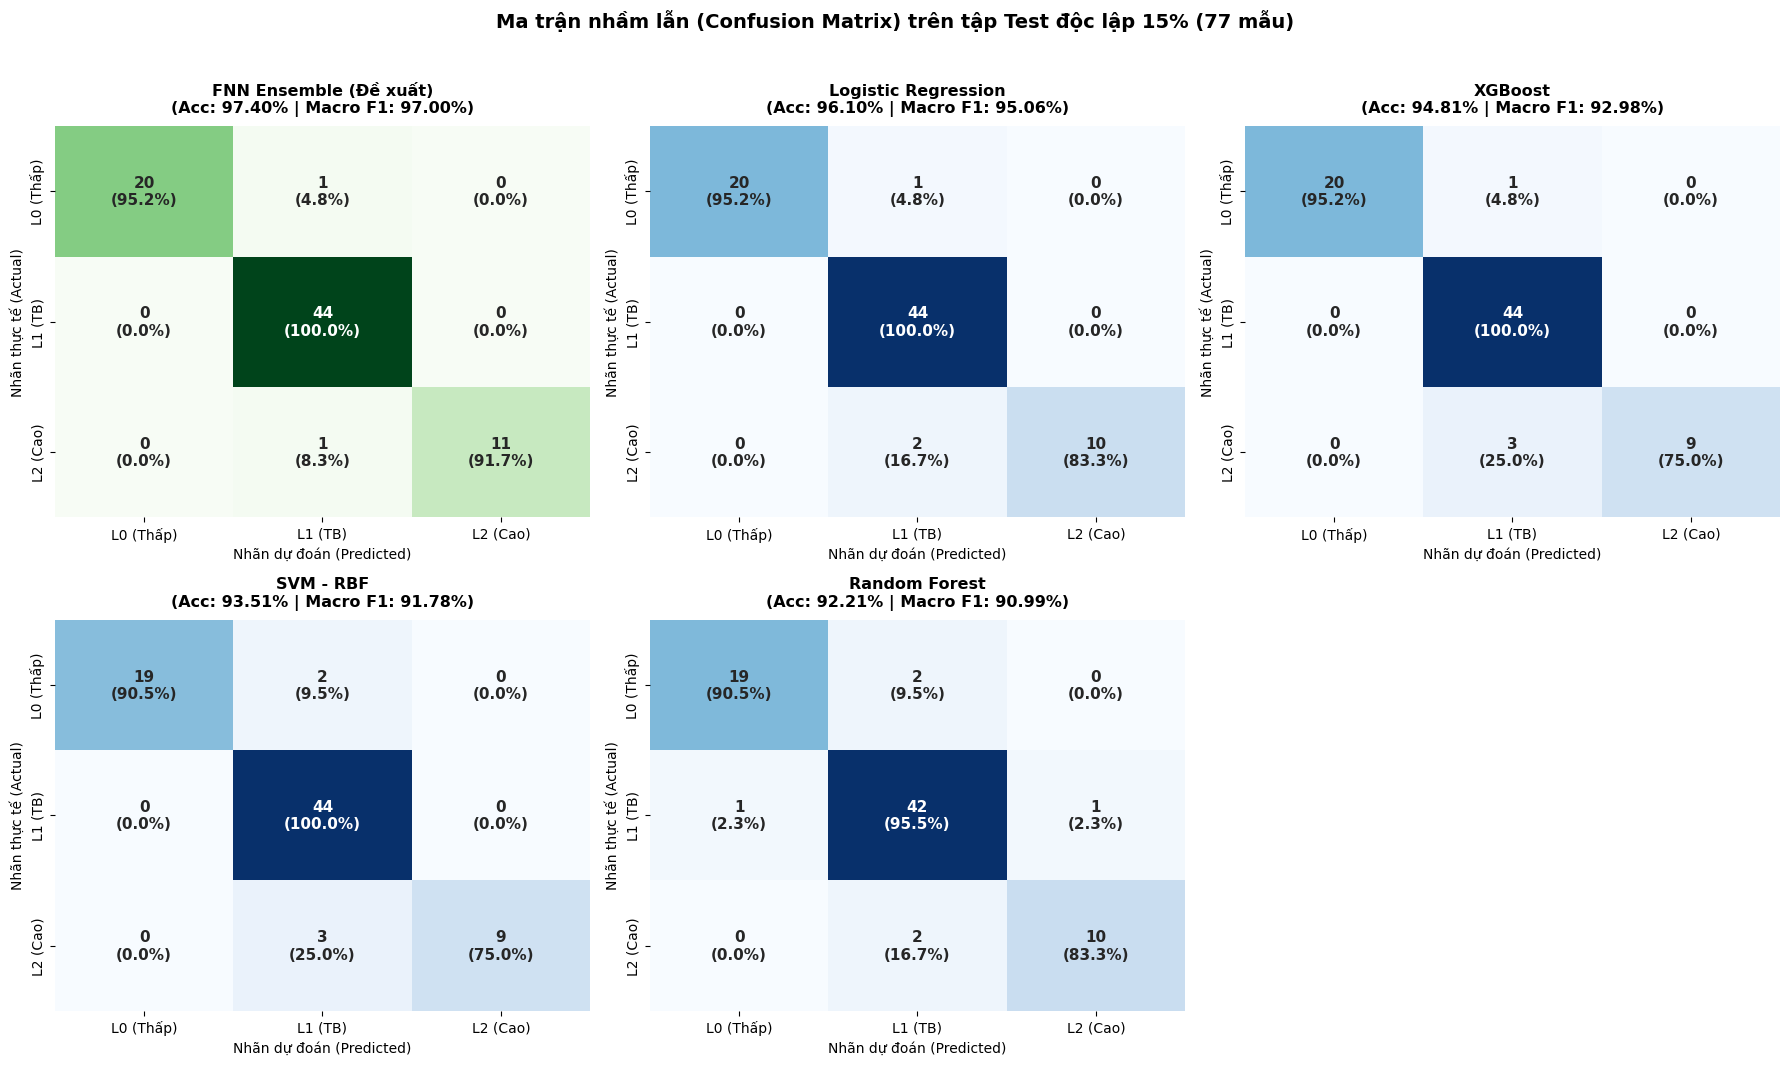

In [ ]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# =========================================================================
# 1. ĐỌC & TIỀN XỬ LÝ DỮ LIỆU ĐỒNG NHẤT VỚI CELL FNN (507 MẪU)
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df1.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce')

valid_idx = Y.notna()
X_original = X_original[valid_idx].apply(pd.to_numeric, errors='coerce')
Y = Y[valid_idx].astype(int)

q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)
    X_original['Q_std']  = X_original[q_cols].std(axis=1)
    X_original['Q_max']  = X_original[q_cols].max(axis=1)

# =========================================================================
# 2. CHIA TẬP DỮ LIỆU CHUNG THEO TỶ LỆ 70% TRAIN - 15% VAL - 15% TEST
# =========================================================================
# Bước 1: Tách 15% Test độc lập (khớp 100% với X_test_raw trong cell FNN)
X_temp, X_test_raw, Y_temp, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.15, random_state=42, stratify=Y
)

# Bước 2: Tách 85% còn lại thành 70% Train và 15% Validation
X_train_70, X_val_15, Y_train_70, Y_val_15 = train_test_split(
    X_temp, Y_temp, test_size=(15 / 85), random_state=42, stratify=Y_temp
)

print(f"📌 Tổng dữ liệu: {len(Y)} mẫu | Train (70%): {len(X_train_70)} | Val (15%): {len(X_val_15)} | Test (15%): {len(X_test_raw)}")

# =========================================================================
# 3. TIỀN XỬ LÝ CHUẨN CHỐNG RÒ RỈ (FIT TRÊN 70% TRAIN -> TRANSFORM VAL & TEST)
# =========================================================================
X_tr = X_train_70.copy()
X_va = X_val_15.copy()
X_te = X_test_raw.copy()

# A. Điền khuyết bằng trung vị của tập Train 70%
train_medians = X_tr.median()
X_tr = X_tr.fillna(train_medians).fillna(0)
X_va = X_va.fillna(train_medians).fillna(0)
X_te = X_te.fillna(train_medians).fillna(0)

# B. Cắt ngoại lai IQR cho 'tg_sudung_dt' theo ngưỡng tập Train 70%
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_tr.columns:
    Q1 = X_tr[feature_outlier].quantile(0.25)
    Q3 = X_tr[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
    X_va[feature_outlier] = np.clip(X_va[feature_outlier], lower_bound, upper_bound)
    X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

# C. Chuẩn hóa StandardScaler
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_va_scaled = scaler.transform(X_va)
X_te_scaled = scaler.transform(X_te)

# D. Cân bằng lớp SMOTE trên tập Train 70%
sm = SMOTE(sampling_strategy='auto', random_state=42)
X_tr_res, Y_tr_res = sm.fit_resample(X_tr_scaled, Y_train_70)

# =========================================================================
# 4. HUẤN LUYỆN CÁC MÔ HÌNH CƠ SỞ TIÊU CHUẨN (KHÔNG DÙNG K-FOLD)
# =========================================================================
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM - RBF': SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='mlogloss', random_state=42)
}

test_preds_dict = {}
val_acc_dict = {}

print("\n🚀 Đang huấn luyện các mô hình cơ sở tiêu chuẩn trên tập Train (70%)...")
for name, clf in baseline_models.items():
    clf.fit(X_tr_res, Y_tr_res)
    val_preds = clf.predict(X_va_scaled)
    val_acc_dict[name] = accuracy_score(Y_val_15, val_preds) * 100
    test_preds_dict[name] = clf.predict_proba(X_te_scaled)
    print(f"✅ Hoàn tất: {name:20s} | Val Acc (15%): {val_acc_dict[name]:.2f}%")

# Ghép kết quả Mô hình FNN Ensemble của bạn (đã chạy trên cùng tập Test 15%)
if 'test_predictions_folds' in globals() and len(test_predictions_folds) == len(X_test_raw):
    test_preds_dict['FNN Ensemble (Đề xuất)'] = test_predictions_folds
    if 'oof_accuracy' in globals():
        val_acc_dict['FNN Ensemble (Đề xuất)'] = oof_accuracy * 100
    else:
        val_acc_dict['FNN Ensemble (Đề xuất)'] = np.nan
else:
    print("\n⚠️ Chưa tìm thấy biến `test_predictions_folds` từ cell FNN phía trên. Hãy chạy cell FNN trước rồi chạy lại cell này!")

# =========================================================================
# 5. BẢNG SO SÁNH PRECISION, RECALL, F1-SCORE & ACCURACY TRÊN TẬP TEST (15%)
# =========================================================================
Y_true_test = Y_test_raw.values
summary_rows = []

for name, pred_probs in test_preds_dict.items():
    y_pred = np.argmax(pred_probs, axis=1)
    f1_classes = f1_score(Y_true_test, y_pred, labels=[0, 1, 2], average=None, zero_division=0)

    summary_rows.append({
        'Mô hình': name,
        'Val Acc (%)': round(val_acc_dict.get(name, np.nan), 2),
        'Test Accuracy (%)': round(accuracy_score(Y_true_test, y_pred) * 100, 2),
        'Macro Precision (%)': round(precision_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100, 2),
        'Macro Recall (%)': round(recall_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100, 2),
        'Macro F1-Score (%)': round(f1_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100, 2),
        'Weighted F1 (%)': round(f1_score(Y_true_test, y_pred, average='weighted', zero_division=0) * 100, 2),
        'F1 L0 (%)': round(f1_classes[0] * 100, 2),
        'F1 L1 (%)': round(f1_classes[1] * 100, 2),
        'F1 L2 (%)': round(f1_classes[2] * 100, 2),
    })

df_compare = pd.DataFrame(summary_rows).sort_values(by='Macro F1-Score (%)', ascending=False).reset_index(drop=True)

print("\n" + "=" * 110)
print(f"📊 BẢNG SO SÁNH FNN ENSEMBLE VỚI CÁC MÔ HÌNH TIÊU CHUẨN (CHIA 70/15/15 - TEST {len(Y_true_test)} MẪU)")
print("=" * 110)
print(df_compare.to_string(index=False))
print("=" * 110)

class_names = ['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)']
for name in df_compare['Mô hình']:
    y_pred = np.argmax(test_preds_dict[name], axis=1)
    print(f"\n--- BÁO CÁO CHI TIẾT PRECISION / RECALL / F1-SCORE: {name} ---")
    print(classification_report(Y_true_test, y_pred, target_names=class_names, digits=4, zero_division=0))

# =========================================================================
# 6. BIỂU ĐỒ 1: SO SÁNH ACCURACY, PRECISION, RECALL & F1-SCORE
# =========================================================================
df_melt = df_compare.melt(
    id_vars='Mô hình',
    value_vars=['Test Accuracy (%)', 'Macro Precision (%)', 'Macro Recall (%)', 'Macro F1-Score (%)'],
    var_name='Chỉ số',
    value_name='Điểm số (%)'
)

plt.figure(figsize=(12, 5.8))
ax = sns.barplot(data=df_melt, x='Mô hình', y='Điểm số (%)', hue='Chỉ số', palette='Set2')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=8.5, padding=2)

plt.title(f'So sánh Hiệu năng Mô hình FNN Đề xuất và Các mô hình Tiêu chuẩn (Chia 70/15/15 - Test {len(Y_true_test)} mẫu)', fontsize=12.5, pad=12)
plt.ylabel('Tỷ lệ (%)', fontsize=11)
plt.xlabel('')
plt.ylim(0, 108)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Chỉ số đánh giá', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('So_sanh_FNN_vs_Baselines_70_15_15.png', dpi=300, bbox_inches='tight')
plt.show()

# =========================================================================
# 7. BIỂU ĐỒ 2: CONFUSION MATRIX CỦA TẤT CẢ MÔ HÌNH TRÊN TẬP TEST 15%
# =========================================================================
ordered_models = df_compare['Mô hình'].tolist()
n_models = len(ordered_models)
ncols = 3
nrows = math.ceil(n_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.2 * nrows))
axes = np.array(axes).reshape(-1)

short_labels = ['L0 (Thấp)', 'L1 (TB)', 'L2 (Cao)']

for idx, name in enumerate(ordered_models):
    ax_cm = axes[idx]
    y_pred = np.argmax(test_preds_dict[name], axis=1)

    cm_count = confusion_matrix(Y_true_test, y_pred, labels=[0, 1, 2])
    cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
    cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

    annot_labels = np.empty_like(cm_count, dtype=object)
    for i in range(cm_count.shape[0]):
        for j in range(cm_count.shape[1]):
            annot_labels[i, j] = f"{cm_count[i, j]}\n({cm_percent[i, j]:.1f}%)"

    cmap_color = 'Greens' if 'FNN' in name else 'Blues'
    acc_val = accuracy_score(Y_true_test, y_pred) * 100
    f1_val = f1_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100

    sns.heatmap(
        cm_count,
        annot=annot_labels,
        fmt='',
        cmap=cmap_color,
        xticklabels=short_labels,
        yticklabels=short_labels,
        annot_kws={"size": 11, "weight": "bold"},
        cbar=False,
        ax=ax_cm
    )
    ax_cm.set_title(f"{name}\n(Acc: {acc_val:.2f}% | Macro F1: {f1_val:.2f}%)", fontsize=11.5, fontweight='bold', pad=10)
    ax_cm.set_xlabel('Nhãn dự đoán (Predicted)', fontsize=10)
    ax_cm.set_ylabel('Nhãn thực tế (Actual)', fontsize=10)

for empty_idx in range(n_models, len(axes)):
    axes[empty_idx].axis('off')

plt.suptitle(f'Ma trận nhầm lẫn (Confusion Matrix) trên tập Test độc lập 15% ({len(Y_true_test)} mẫu)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Confusion_Matrix_FNN_vs_Baselines_70_15_15.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df3 = pd.read_csv('drive/MyDrive/Training_data/smartphone_addiction3.csv')
df = pd.concat([df1, df2, df3], ignore_index=True)
# Kiểm tra sự nhất quán giữa tổng điểm Q1-Q10 và nhãn Level trên toàn bộ 605 mẫu
q_cols = [f'Q{i}' for i in range(1, 11) if f'Q{i}' in df.columns]
df_check = df
df_check['Tong_Q'] = df_check[q_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1)

print("=== PHÂN BỐ TỔNG ĐIỂM Q1-Q10 THEO TỪNG NHÃN LEVEL ===")
print(df_check.groupby('Level')['Tong_Q'].agg(['count', 'min', 'median', 'max']))

# Kiểm tra xem có mức tổng điểm nào bị trùng chéo giữa các nhãn Level không
overlap = df_check.groupby('Tong_Q')['Level'].nunique()
print("\nCác mức tổng điểm Q bị gán nhiều hơn 1 nhãn Level:", overlap[overlap > 1].index.tolist())

=== PHÂN BỐ TỔNG ĐIỂM Q1-Q10 THEO TỪNG NHÃN LEVEL ===
       count  min  median  max
Level                         
0        151   10    17.0   27
1        334   10    26.0   40
2        117   29    39.0   60

Các mức tổng điểm Q bị gán nhiều hơn 1 nhãn Level: [10, 13, 16, 17, 18, 19, 20, 21, 22, 24, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
